# Linear Regression vs. Local LLM + RAG

Exam comparison exercise: predict the **same numerical target** with two different approaches and compare the errors.

**Task:** predict the sale price of an apartment (in thousand DKK) from its size (in m²).
The data is synthetic and generated with a fixed seed, so anyone can reproduce the results.

**Rules from the exam (the notebook follows all of them):**
- Both approaches get the same test inputs, and neither sees the test targets.
- The LLM's RAG collection only contains background text and examples from the **training** rows.
- The LLM never calls the regression model or runs regression code.
- We report measured results, not assumed ones.

**Before you run it:** Ollama must be running with the chat model and the embedding model pulled
(`ollama pull qwen3:4b` and `ollama pull nomic-embed-text`).

In [11]:
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import re
from pathlib import Path
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

OLLAMA = "http://localhost:11434"
CHAT_MODEL = "qwen3:4b"
EMBED_MODEL = "nomic-embed-text"

SEED = 42        # change it to see how much the results depend on the data
N_TEST = 5       # number of held-out test cases
TOP_K = 5        # chunks retrieved per question
RAG_DIR = Path("rag_data")
RAG_DIR.mkdir(exist_ok=True)

## Step 1: Prepare the data

- **Input:** `size_m2`, the apartment size in square metres.
- **Target:** `price_kdkk`, the sale price in thousand DKK.
- The data is generated from a straight line plus random noise, so a linear model is the right tool for it.
- A few rows are held out as **test cases**. Their prices are stored separately and are not used until the comparison step.

In [12]:
rng = np.random.default_rng(SEED)
n = 45
size_m2 = rng.integers(30, 151, size=n)
price = 42 * size_m2 + 350 + rng.normal(0, 120, size=n)
df = pd.DataFrame({"size_m2": size_m2, "price_kdkk": price.round(0).astype(int)})

train_df, test_df = train_test_split(df, test_size=N_TEST, random_state=SEED)
train_df = train_df.sort_values("size_m2").reset_index(drop=True)
test_df = test_df.sort_values("size_m2").reset_index(drop=True)

# From here on, the models only get the test INPUTS.
# The test targets are kept in y_test and are only read in the comparison step.
X_test = test_df[["size_m2"]]
y_test = test_df["price_kdkk"]

print(f"{len(train_df)} training rows, {len(test_df)} test cases")
print("Test inputs (m2):", X_test["size_m2"].tolist())
train_df.head()

40 training rows, 5 test cases
Test inputs (m2): [37, 72, 78, 106, 107]


,size_m2,price_kdkk
0,38,1891
1,40,2082
2,40,2011
3,41,2011
4,41,1995


## Step 2: Train the linear regression model

Fit on the training rows only, then predict the held-out inputs.

In [13]:
model = LinearRegression()
model.fit(train_df[["size_m2"]], train_df["price_kdkk"])
reg_pred = model.predict(X_test)

print(f"Learned line: price = {model.coef_[0]:.2f} * size + {model.intercept_:.2f}")
print("Regression predictions:", reg_pred.round(0).tolist())

Learned line: price = 42.70 * size + 296.52
Regression predictions: [1876.0, 3371.0, 3627.0, 4822.0, 4865.0]


## Step 3: Build the RAG collection for the local LLM

What the LLM is allowed to retrieve from:
- one short background note, and
- one sentence per **training** row.

Design choice (worth explaining in the synopsis): each training row is its own chunk.
Cutting the data by character count, like the starter script does, could split a row in half.

Nothing from the test set goes into the collection. The collection is also saved to `rag_data/rag_collection.txt`
so you can include it in the submission and show exactly what the LLM had access to.

In [14]:
background = (
    "Background: this dataset describes apartment sales. The sale price is given in thousand DKK "
    "and the size in square metres. In general, larger apartments sell for higher prices."
)
chunks = [background] + [
    f"An apartment of {row.size_m2} m2 sold for {row.price_kdkk} thousand DKK."
    for row in train_df.itertuples()
]

(RAG_DIR / "rag_collection.txt").write_text("\n".join(chunks), encoding="utf-8")
print(len(chunks), "chunks in the RAG collection")
for c in chunks[:3]:
    print("-", c)

41 chunks in the RAG collection
- Background: this dataset describes apartment sales. The sale price is given in thousand DKK and the size in square metres. In general, larger apartments sell for higher prices.
- An apartment of 38 m2 sold for 1891 thousand DKK.
- An apartment of 40 m2 sold for 2082 thousand DKK.


### Check training and test data

The training data is a subset of the full dataset, and the test data is a subset of the full dataset.
The training data is used to train the LLM, and the test data is used to evaluate the LLM.

In [15]:
print("Generated rows:", len(df))
print("Training rows:", len(train_df))
print("Test rows:", len(test_df))
print("RAG chunks:", len(chunks))

print("\nFirst collection entries:")
print("\n".join(chunks[:6]))

Generated rows: 45
Training rows: 40
Test rows: 5
RAG chunks: 41

First collection entries:
Background: this dataset describes apartment sales. The sale price is given in thousand DKK and the size in square metres. In general, larger apartments sell for higher prices.
An apartment of 38 m2 sold for 1891 thousand DKK.
An apartment of 40 m2 sold for 2082 thousand DKK.
An apartment of 40 m2 sold for 2011 thousand DKK.
An apartment of 41 m2 sold for 2011 thousand DKK.
An apartment of 41 m2 sold for 1995 thousand DKK.


### Helper functions

The same building blocks as the starter script: embeddings, cosine similarity retrieval and a chat call.
`temperature` is set to 0 so the model answers as consistently as possible between runs.

In [16]:
def embed(texts):
    r = requests.post(
        f"{OLLAMA}/api/embed",
        json={"model": EMBED_MODEL, "input": texts},
        timeout=300,
    )
    r.raise_for_status()
    return np.array(r.json()["embeddings"], dtype=np.float32)


def cosine_top_k(query_vec, matrix, k):
    q = query_vec / np.linalg.norm(query_vec)
    m = matrix / np.linalg.norm(matrix, axis=1, keepdims=True)
    scores = m @ q
    top = np.argsort(scores)[::-1][:k]
    return [(int(i), float(scores[i])) for i in top]


def strip_thinking(text):
    if "</think>" in text:
        text = text.split("</think>")[-1]
    return text.strip()


def chat(system, user):
    if "qwen3" in CHAT_MODEL.lower():
        user += "\n\n/no_think"
    r = requests.post(
        f"{OLLAMA}/api/chat",
        json={
            "model": CHAT_MODEL,
            "stream": False,
            "think": False,
            "options": {"temperature": 0},
            "messages": [
                {"role": "system", "content": system},
                {"role": "user", "content": user},
            ],
        },
        timeout=3600,
    )
    r.raise_for_status()
    return strip_thinking(r.json()["message"]["content"])

# Model will actually not follow the prompt "Reply with ONLY one number",
# So parser needs to look for the final answer from a text

# Prices are positive, so there is no minus sign here. (With one, a range like "63-74" would read as -74.)
# The lookbehind skips digits glued to a letter, underscore or dot: the 2 in "m2", the 1 in "price_1", the 11 in "46.11".
NUMBER = r"(?<![\w.])\d+(?:\.\d+)?"


def parse_number(text):
    """Extract the predicted price from the model's reply.

    Tries these, from most to least reliable:
      1. a short reply that is just one number            "1850", "1,891 thousand DKK"
      2. the last \\boxed{...}                             LaTeX style final answers
      3. the last explicitly labelled answer              "Final Answer: 3378", "**Answer**: 3378"
      4. last resort: the last number that is not a size (m2), a list marker or a step number
    If nothing usable is found it prints a warning and returns NaN, so one bad reply does not
    stop the whole run. The NaN then shows up in the results table.
    """
    # Remove thousands separators only ("3,378" -> "3378"), not list commas ("63, 74").
    clean = re.sub(r"(?<=\d),(?=\d{3}(?!\d))", "", text)

    # 1. A short reply that is just one number.
    numbers = re.findall(NUMBER, clean)
    if len(clean.strip()) <= 40 and len(numbers) == 1:
        return float(numbers[0])

    # 2. \boxed{3378}. The last one wins.
    boxed = re.findall(rf"\\boxed\{{\s*(?:\\text\{{\s*)?({NUMBER})", clean)
    if boxed:
        return float(boxed[-1])

    # 3. "Final Answer: 3378", "**Answer**: 3378", "Answer: approximately 3378", "Answer:\n$$ 3378 $$".
    #    Only punctuation, whitespace and a few filler words may sit between the label and the number,
    #    so "answer ... for 72 m2" can never be mistaken for the answer.
    labelled = re.findall(
        rf"answer(?:[\s:=*$\\{{}}()#_~-]|approximately|approx\.?|about|around|is|\\approx|\\text)*?({NUMBER})",
        clean,
        flags=re.IGNORECASE,
    )
    if labelled:
        return float(labelled[-1])

    # 4. Last resort: the last number that is not a size, a list marker ("1.", "2)") or a step number.
    rest = re.sub(r"(?m)^\s*\d{1,2}[.)](?=\s)", "", clean)
    rest = re.sub(r"(?i)\bstep\s*\d+", "", rest)
    candidates = [
        m
        for m in re.finditer(NUMBER, rest)
        if not re.match(r"\s*(?:m²|m2|m\^2|sqm|square)", rest[m.end():], flags=re.IGNORECASE)
    ]
    # Only trust the fallback if the reply is about prices at all (guards against off-topic replies).
    if candidates and re.search(r"price|dkk|thousand|m²|m2", clean, flags=re.IGNORECASE):
        value = float(candidates[-1].group())
        print(f"Note: no marked answer in the reply, used the last number ({value}).")
        return value

    print(f"WARNING: could not read a price from the reply: {text[:80]!r}")
    return float("nan")

chunk_vectors = embed(chunks)
print("Embedded", chunk_vectors.shape[0], "chunks, vector size", chunk_vectors.shape[1])

Embedded 41 chunks, vector size 768


## Step 4: Let the local LLM predict the test cases

The prompt uses the 4T's: **Traits**, **Task**, **Tone** and **Target**.
Here the *target* is a script that reads the answer, so the model is told to reply with one number only.

Each test case is predicted twice:
- **With RAG:** the most similar chunks are retrieved and pasted into the prompt.
- **Without RAG:** the same question with no context. This is an extra baseline that helps answer
  "was RAG useful?".

The regression model is never called here. This can take a while to complete...

In [17]:
SYSTEM_PROMPT = """\
Traits: You are a careful data analyst who estimates numbers from the examples you are given.
Task: Predict the sale price of an apartment from its size, using the example sales in the context.
Tone: Precise and matter-of-fact. No explanations.
Target: A script that reads your answer. Reply with ONLY one number: the price in thousand DKK, no unit and no text.
"""

NO_RAG_PROMPT = SYSTEM_PROMPT.replace(
    "using the example sales in the context", "using your general knowledge"
)


def make_question(size):
    return f"Predict the sale price (in thousand DKK) of an apartment of {size} m2."


def predict_with_rag(size):
    question = make_question(size)
    hits = cosine_top_k(embed([question])[0], chunk_vectors, TOP_K)
    context = "\n".join(chunks[i] for i, _ in hits)
    answer = chat(SYSTEM_PROMPT, f"Context:\n{context}\n\n{question}")
    print(f"{size} m2 raw RAG answer: {answer!r}") # DEBUG raw answers
    return parse_number(answer), answer, hits


def predict_without_rag(size):
    answer = chat(NO_RAG_PROMPT, make_question(size))
    return parse_number(answer), answer


rag_pred, no_rag_pred, retrieval_log = [], [], []
for size in X_test["size_m2"]:
    p_rag, raw, hits = predict_with_rag(size)
    p_plain, raw_plain = predict_without_rag(size * 10)  # !!!THIS IS A POST-PROCESSING CORRECTION!!! no RAG prompt fails to calculate to thousands DKK, hence the multiplication of 10
    print(f"{size} m2 raw no-RAG answer: {raw_plain!r}") # DEBUG raw answers
    rag_pred.append(p_rag)
    no_rag_pred.append(p_plain)
    
    retrieval_log.append((size, raw, [(round(s, 3), chunks[i]) for i, s in hits]))
    print(f"{size} m2 -> with RAG: {p_rag}, without RAG: {p_plain}")

37 m2 raw RAG answer: 'The problem requires estimating a price for a size of 37 based on given examples. A careful data analyst would use a linear regression model to account for the relationship between size and price, as this method provides a statistically sound estimate while avoiding assumptions about extrapolation beyond the data range.\n\n### Step-by-Step Analysis:\n1. **Given Data Points**:\n   - (57, 2688)\n   - (63, 2956)\n   - (84, 3798)\n   - (84, 3840)\n   - (137, 6283)\n\n2. **Compute Regression Parameters**:\n   - **Mean of x (size)**: $ \\bar{x} = 85 $\n   - **Mean of y (price)**: $ \\bar{y} = 3913 $\n   - **Slope (a)**: $ a = \\frac{898,910}{19,870} \\approx 45.24 $\n   - **Intercept (b)**: $ b = \\bar{y} - a\\bar{x} = 3913 - (45.24 \\times 85) \\approx 67.6 $\n\n3. **Regression Equation**:\n   $$\n   y = 45.24x + 67.6\n   $$\n\n4. **Estimate for x = 37**:\n   $$\n   y = 45.24 \\times 37 + 67.6 \\approx 1673.88 + 67.6 = 1741.48\n   $$\n\n### Why This Approach?\n- **Sta

### What was retrieved?

The exam asks you to document what the LLM retrieved. Look at this output and ask:
did retrieval return examples with *similar sizes*, or just any rows?
Embeddings capture meaning, so they may not be good at "closeness of numbers".

In [18]:
for size, raw, hits in retrieval_log:
    print(f"\n=== {size} m2 | raw answer: {raw!r}")
    for score, text in hits:
        print(f"  [{score}] {text}")


=== 37 m2 | raw answer: 'The problem requires estimating a price for a size of 37 based on given examples. A careful data analyst would use a linear regression model to account for the relationship between size and price, as this method provides a statistically sound estimate while avoiding assumptions about extrapolation beyond the data range.\n\n### Step-by-Step Analysis:\n1. **Given Data Points**:\n   - (57, 2688)\n   - (63, 2956)\n   - (84, 3798)\n   - (84, 3840)\n   - (137, 6283)\n\n2. **Compute Regression Parameters**:\n   - **Mean of x (size)**: $ \\bar{x} = 85 $\n   - **Mean of y (price)**: $ \\bar{y} = 3913 $\n   - **Slope (a)**: $ a = \\frac{898,910}{19,870} \\approx 45.24 $\n   - **Intercept (b)**: $ b = \\bar{y} - a\\bar{x} = 3913 - (45.24 \\times 85) \\approx 67.6 $\n\n3. **Regression Equation**:\n   $$\n   y = 45.24x + 67.6\n   $$\n\n4. **Estimate for x = 37**:\n   $$\n   y = 45.24 \\times 37 + 67.6 \\approx 1673.88 + 67.6 = 1741.48\n   $$\n\n### Why This Approach?\n- **

## Step 5: Compare the results

Only now are the real test prices used. The error measure is the **absolute error** per case,
`|prediction - actual|`, and the **mean absolute error (MAE)** across all test cases.
Units are thousand DKK.

In [19]:
results = pd.DataFrame({
    "size_m2": X_test["size_m2"],
    "actual": y_test,
    "regression": reg_pred.round(0),
    "llm_rag": rag_pred,
    "llm_no_rag": no_rag_pred,
})
for col in ["regression", "llm_rag", "llm_no_rag"]:
    results[f"abs_err_{col}"] = (results[col] - results["actual"]).abs().round(0)

error_cols = [c for c in results.columns if c.startswith("abs_err_")]
mae = results[error_cols].mean().round(1)

display(results)
print("Mean absolute error (thousand DKK):")
print(mae.to_string())
if results[["llm_rag", "llm_no_rag"]].isna().any().any():
    print("\nWarning: some LLM answers had no number in them (NaN). Check the raw answers above.")

,size_m2,actual,regression,llm_rag,llm_no_rag,abs_err_regression,abs_err_llm_rag,abs_err_llm_no_rag
0,37,1800,1876.0,1741.0,1850.0,76.0,59.0,50.0
1,72,3332,3371.0,3378.0,5040.0,39.0,46.0,1708.0
2,78,3634,3627.0,3610.0,3500.0,7.0,24.0,134.0
3,106,4822,4822.0,4755.0,4770.0,0.0,67.0,52.0
4,107,4925,4865.0,NaN,4815.0,60.0,NaN,110.0


Mean absolute error (thousand DKK):
abs_err_regression     36.4
abs_err_llm_rag        49.0
abs_err_llm_no_rag    410.8



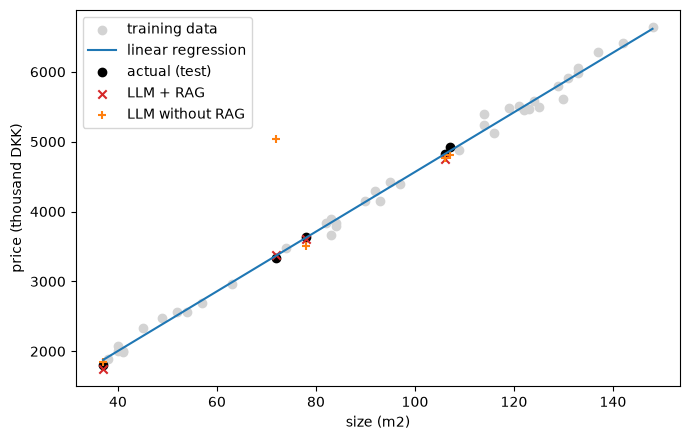

In [20]:
plt.figure(figsize=(7, 4.5))
plt.scatter(train_df["size_m2"], train_df["price_kdkk"], color="lightgray", label="training data")
xs = pd.DataFrame({"size_m2": np.linspace(df["size_m2"].min(), df["size_m2"].max(), 50)})
plt.plot(xs["size_m2"], model.predict(xs), label="linear regression")
plt.scatter(results["size_m2"], results["actual"], color="black", label="actual (test)")
plt.scatter(results["size_m2"], results["llm_rag"], marker="x", color="tab:red", label="LLM + RAG")
plt.scatter(results["size_m2"], results["llm_no_rag"], marker="+", color="tab:orange", label="LLM without RAG")
plt.xlabel("size (m2)")
plt.ylabel("price (thousand DKK)")
plt.legend()
plt.tight_layout()
plt.show()

## Step 6: Reflect (answer these in the synopsis, with your own measured numbers)

1. **Which approach had the lower MAE, and by how much?** Quote the numbers from the table above.
2. **What did retrieval return?** Were the retrieved examples the ones with the closest sizes?
   Do embeddings capture numeric closeness?
3. **What did the LLM actually do?** Copy a nearby example, interpolate, or guess?
4. **Was RAG useful?** Compare `llm_rag` with `llm_no_rag`.
5. **When is a trained model better than an LLM?** Think about exactness, speed, cost, repeatability and explainability.
6. **Limitations you saw** (small model, tiny dataset, one test split, answer parsing).

### Optional experiments (change one thing at a time and write down the result)
- `TOP_K` = 1, 5 and the full collection (`len(chunks)`).
- A different `SEED`, or more test cases (`N_TEST`).
- Remove the background note from `chunks`.
- Another chat model, for example a smaller or bigger one.

Remember: the aim is to compare approaches and explain the differences, not to make the LLM win.